In [53]:
#Bolli Yaswanth Melki , 92400133114 , 5EK2B , CNN

In [54]:
import numpy as np
import numpy.random as nr
try:
    from tensorflow import set_random_seed
except ImportError:
    from tensorflow.random import set_seed as set_random_seed
import matplotlib.pyplot as plt
import keras
from keras.datasets import mnist
try:
    import keras.utils.np_utils as ku
except ImportError:
    from keras import utils as ku
import keras.models as models
import keras.layers as layers
from keras import regularizers
from keras.layers import Dropout
try:
    from keras.optimizers import rmsprop, Adam
except ImportError:
    from keras.optimizers import RMSprop as rmsprop, Adam

%matplotlib inline

In [55]:
nr.seed(12233)
kernel = np.array([0.25, 0.5, 0.25])

def conv_1d(series, kernel):
    '''Performs simple 1d convolution over the series values
    given the kernel weights. This function only works for
    kernels with odd span'''
    out =[]
    span = kernel.shape[0]
    half_span = int((span - 1)/2)
    len = series.shape[0]
    for i in range(0, len - span):
        out.append(np.dot(series[i:i+span], kernel))
    return np.array(out)

series = np.concatenate((nr.normal(size = 40), nr.normal(size = 40) + 2.0))
result = conv_1d(series, kernel)

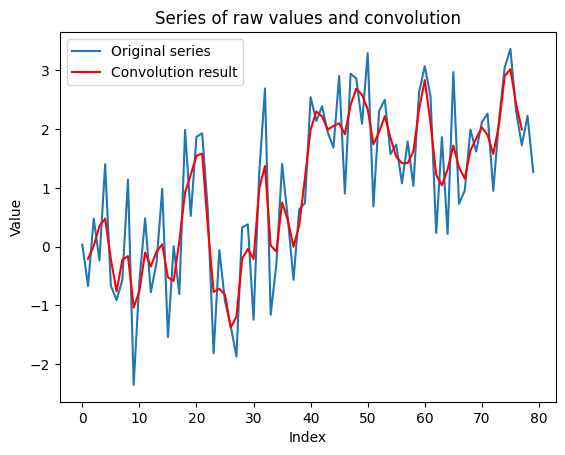

In [56]:
def plot_conv(series, conv, span):
    x = list(range(series.shape[0]))
    offset = int((span-1)/2)
    end = series.shape[0] - offset -1
    plt.plot(x, series, label = 'Original series')
    plt.plot(x[offset:end], conv, color = 'red', label = 'Convolution result')
    plt.legend()
    plt.xlabel('Index')
    plt.ylabel('Value')
    plt.title('Series of raw values and convolution')

plot_conv(series, result, 3)

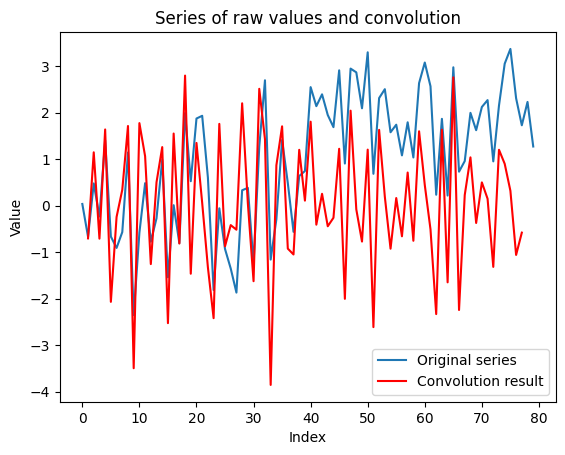

In [57]:
kernel = np.array([-1.0,1.0,0.0])
result = conv_1d(series, kernel)
plot_conv(series, result, 3)

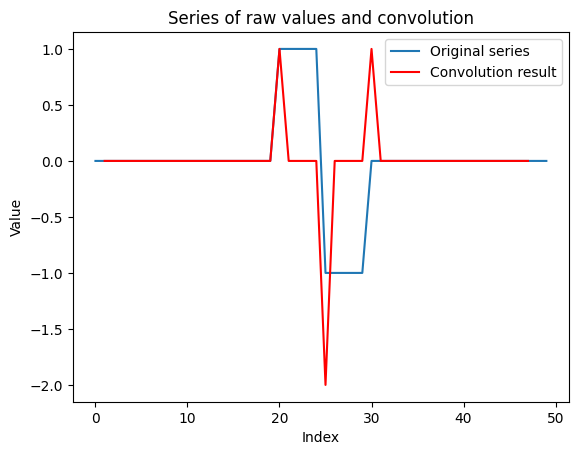

In [58]:
nr.seed(12233)
series1 = np.concatenate((np.zeros((20,)), np.zeros((5,)) + 1.0, np.zeros((5,)) - 1.0, np.zeros((20,))))
kernel1 = np.array([-1.0, 1.0, 0.0])
result1 = conv_1d(series1, kernel1)
plot_conv(series1, result1, 3)

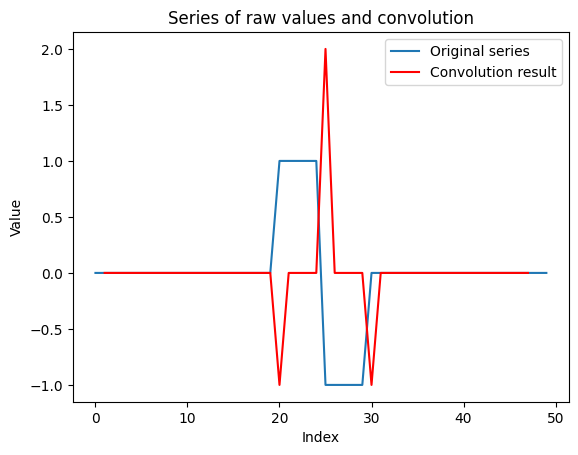

In [59]:
kernel2 = np.array([1.0, -1.0, 0.0])
result2 = conv_1d(series1, kernel2)
plot_conv(series1, result2, 3)

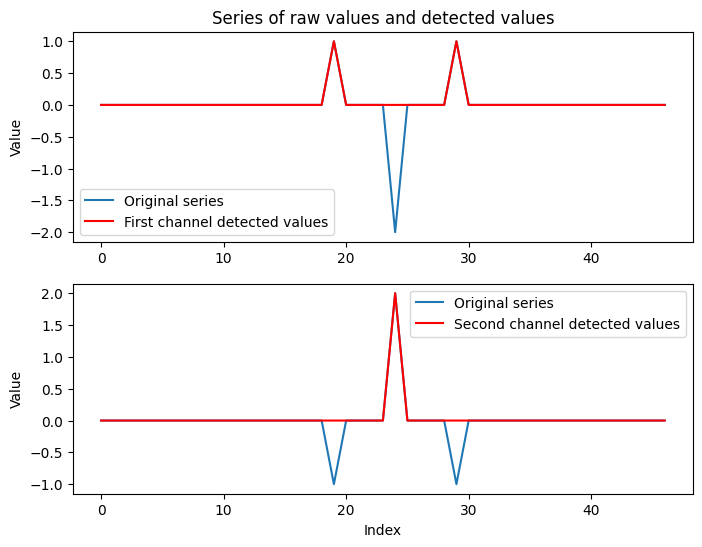

In [60]:
def relu(series):
    return np.array([x if x > 0.0 else 0.0 for x in series])

def plot_detect(series, series2, detect1, detect2):
    x = list(range(series.shape[0]))
    fig = plt.figure(figsize=(8,6))
    ## First channel
    plt.subplot(2, 1, 1)
    plt.plot(x, series, label = 'Original series')
    plt.plot(x, detect1, color = 'red', label = 'First channel detected values')
    plt.legend()
    plt.ylabel('Value')
    plt.title('Series of raw values and detected values')
    ## Second channel
    plt.subplot(2, 1, 2)
    plt.plot(x, series2, label = 'Original series')
    plt.plot(x, detect2, color = 'red', label = 'Second channel detected values')
    plt.legend()
    plt.xlabel('Index')
    plt.ylabel('Value')

detect1 = relu(result1)
detect2 = relu(result2)
plot_detect(result1, result2, detect1, detect2)

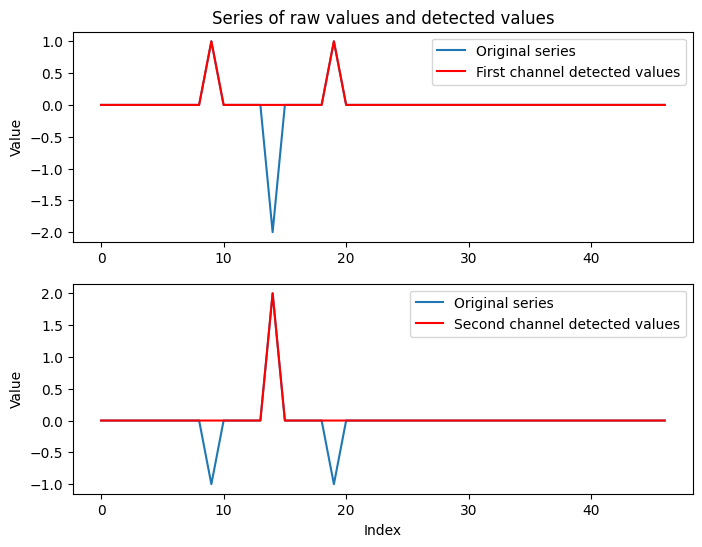

In [61]:
nr.seed(12233)
series2 = np.concatenate((np.zeros((10,)), np.zeros((5,)) + 1.0, np.zeros((5,)) - 1.0, np.zeros((30,))))
result21 = conv_1d(series2, kernel1)
detect21 = relu(result21)
result22 = conv_1d(series2, kernel2)
detect22 = relu(result22)
plot_detect(result21, result22, detect21, detect22)

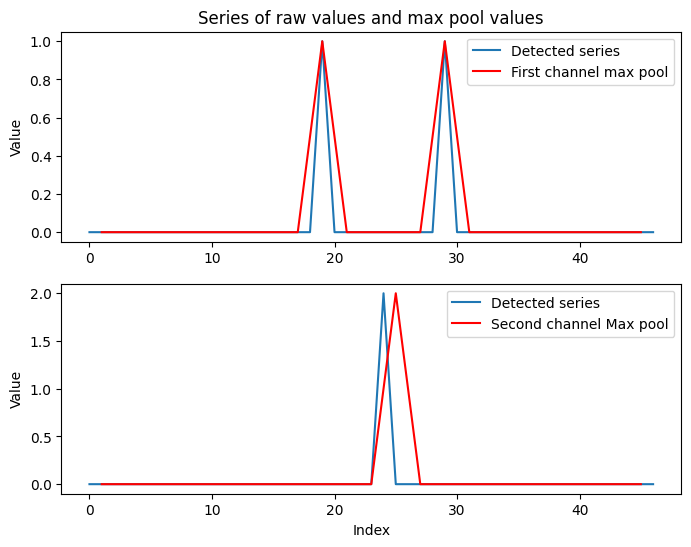

In [62]:
def max_pool_2(series):
    '''Performs simple 1d max pooling with
    an operator span of 2 and stride 2'''
    out =[]
    len = series.shape[0]
    for i in range(0, len - 1, 2):
        out.append(np.max(series[i:i+2]))
    return np.array(out)

def plot_pool(series1, series2, pool1, pool2):
    x = list(range(series1.shape[0]))
    end = series1.shape[0]
    fig = plt.figure(figsize=(8,6))
    ## First channel
    plt.subplot(2, 1, 1)
    plt.plot(x, series1, label = 'Detected series')
    plt.plot(x[1:end:2], pool1, color = 'red', label = 'First channel max pool')
    plt.legend()
    plt.ylabel('Value')
    plt.title('Series of raw values and max pool values')
    ## Second channel
    plt.subplot(2, 1, 2)
    plt.plot(x, series2, label = 'Detected series')
    plt.plot(x[1:end:2], pool2, color = 'red', label = 'Second channel Max pool')
    plt.legend()
    plt.xlabel('Index')
    plt.ylabel('Value')

pool1 = max_pool_2(detect1)
pool2 = max_pool_2(detect2)
plot_pool(detect1, detect2, pool1, pool2)

In [63]:
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
train_images = train_images.reshape((60000, 28, 28, 1)).astype('float')/255
print(train_images.shape)
print(train_images.dtype)
print(test_images.shape, test_labels.shape)
test_images = test_images.reshape((10000, 28, 28, 1)).astype('float')/255
print(test_images.shape)
train_labels = ku.to_categorical(train_labels)
print(train_labels[5:,])
test_labels = ku.to_categorical(test_labels)

(60000, 28, 28, 1)
float64
(10000, 28, 28) (10000,)
(10000, 28, 28, 1)
[[0. 0. 1. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 1. 0.]]


In [64]:
## Set up and call-backs for early stopping
filepath = 'my_model_file.h5' # define where the model is saved (.h5 or .keras)
callbacks_list = [
        keras.callbacks.EarlyStopping(
            monitor = 'val_loss', # Use validation loss to monitor the model
            patience = 1 # Stop after one step with worse val_loss
        ),
        keras.callbacks.ModelCheckpoint(
            filepath = filepath, # file where the checkpoint is saved
            monitor = 'val_loss', # Don't overwrite the saved model unless val_loss improves
            save_best_only = True # Only save model if it is the best
        )
]

In [65]:
## Define the Sequential model as usual.
nns = models.Sequential()

## Add some convolutional layers to extract features
## from the images with padding added to the convolution layers.
nns.add(layers.Conv2D(32, (3, 3), padding = 'same', activation = 'relu', input_shape = (28, 28, 1)))
nns.add(layers.MaxPooling2D((2, 2)))
nns.add(layers.Conv2D(64, (3, 3), padding = 'same', activation = 'relu'))
nns.add(layers.MaxPooling2D((2, 2)))
nns.add(layers.Conv2D(64, (3, 3), padding = 'same', activation = 'relu'))

## Now flatten the output of the convolutional layers so
## a fully connected network can be applied.
nns.add(layers.Flatten())

## Finally, fully connected layers to classify the digits
## Using the features extracted by the convolutional layers.
nns.add(layers.Dense(64, activation = 'relu',
                        kernel_regularizer=regularizers.l2(0.01)))
nns.add(Dropout(0.5))
nns.add(layers.Dense(10, activation = 'softmax'))

nns.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       200,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 257,162 (1004.54 KB)

 Trainable params: 257,162 (1004.54 KB)

 Non-trainable params: 0 (0.00 B)

In [66]:
## Compile the model
nr.seed(2323)
set_random_seed(4466)
nns.compile(optimizer = 'rmsprop', loss = 'categorical_crossentropy',
                metrics = ['accuracy'])

## Now fit the model
nr.seed(88776)
set_random_seed(5666)
history_s = nns.fit(train_images, train_labels,
                  epochs = 40, batch_size = 128,
                  validation_data = (test_images, test_labels),
                  callbacks = callbacks_list,
                  verbose = 1)

Epoch 1/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step - accuracy: 0.7721 - loss: 1.0305

469/469 ━━━━━━━━━━━━━━━━━━━━ 83s 174ms/step - accuracy: 0.8887 - loss: 0.5462 - val_accuracy: 0.9728 - val_loss: 0.1703
Epoch 2/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - accuracy: 0.9581 - loss: 0.2220

469/469 ━━━━━━━━━━━━━━━━━━━━ 79s 169ms/step - accuracy: 0.9614 - loss: 0.2045 - val_accuracy: 0.9773 - val_loss: 0.1283
Epoch 3/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.9674 - loss: 0.1646

469/469 ━━━━━━━━━━━━━━━━━━━━ 78s 166ms/step - accuracy: 0.9699 - loss: 0.1570 - val_accuracy: 0.9843 - val_loss: 0.1007
Epoch 4/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.9735 - loss: 0.1423

469/469 ━━━━━━━━━━━━━━━━━━━━ 82s 166ms/step - accuracy: 0.9749 - loss: 0.1368 - val_accuracy: 0.9829 - val_loss: 0.1002
Epoch 5/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - accuracy: 0.9766 - loss: 0.1233

469/469 ━━━━━━━━━━━━━━━━━━━━ 77s 164ms/step - accuracy: 0.9775 - loss: 0.1217 - val_accuracy: 0.9874 - val_loss: 0.0773
Epoch 6/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 76s 162ms/step - accuracy: 0.9788 - loss: 0.1126 - val_accuracy: 0.9858 - val_loss: 0.0795


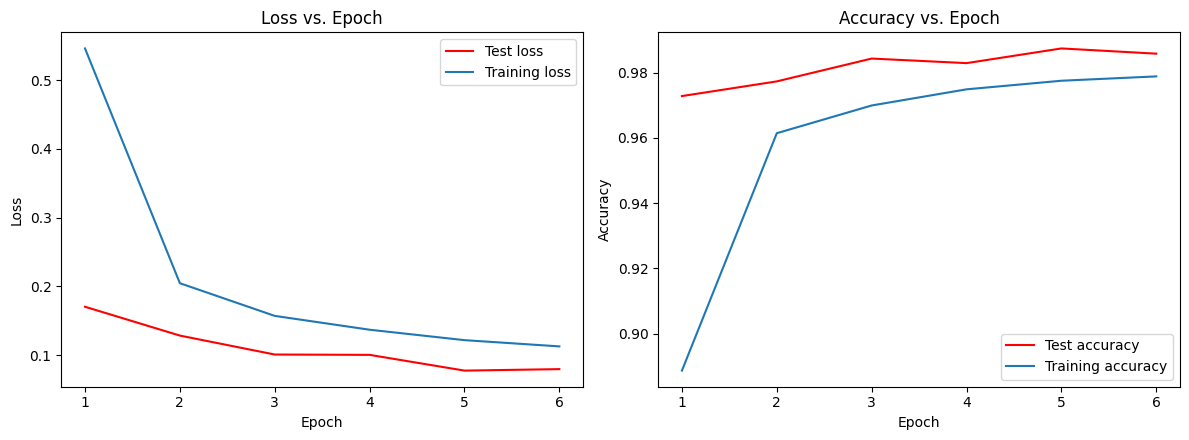

In [69]:
def plot_loss(history):
    """Function to plot the loss vs. epoch"""
    train_loss = history.history["loss"]
    test_loss = history.history["val_loss"]
    x = list(range(1, len(test_loss) + 1))
    plt.plot(x, test_loss, color="red", label="Test loss")
    plt.plot(x, train_loss, label="Training loss")
    plt.legend()
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Loss vs. Epoch")


def plot_accuracy(history):
    train_acc = history.history.get("acc", history.history.get("accuracy"))
    test_acc = history.history.get("val_acc", history.history.get("val_accuracy"))
    x = list(range(1, len(test_acc) + 1))
    plt.plot(x, test_acc, color="red", label="Test accuracy")
    plt.plot(x, train_acc, label="Training accuracy")
    plt.legend()
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Accuracy vs. Epoch")


plt.figure(figsize=(12, 4.5))
plt.subplot(1, 2, 1)
plot_loss(history_s)

plt.subplot(1, 2, 2)
plot_accuracy(history_s)

plt.tight_layout()
plt.show()

(28, 28, 1)


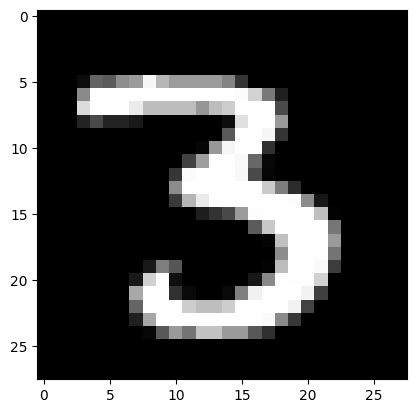

In [70]:
img = train_images[12,:,:,:]
print(img.shape)
plt.imshow(img.reshape((28,28)), cmap = 'gray')

In [72]:
nn = models.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.Flatten(),
    layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(0.01)),
    Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])

nn.compile(
    optimizer="rmsprop",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

nr.seed(2356)
set_random_seed(2333)
history = nn.fit(
    train_images,
    train_labels,
    epochs=40,
    batch_size=128,
    validation_data=(test_images, test_labels),
    callbacks=callbacks_list,
    verbose=1,
)

layer_outputs = [layer.output for layer in nn.layers[:7]]
activation_model = models.Model(inputs=nn.inputs, outputs=layer_outputs)
activations = activation_model.predict(img.reshape(1, 28, 28, 1))

Epoch 1/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 49s 102ms/step - accuracy: 0.8811 - loss: 0.6674 - val_accuracy: 0.9318 - val_loss: 0.3090
Epoch 2/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 45s 96ms/step - accuracy: 0.9671 - loss: 0.1821 - val_accuracy: 0.9724 - val_loss: 0.1352
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step


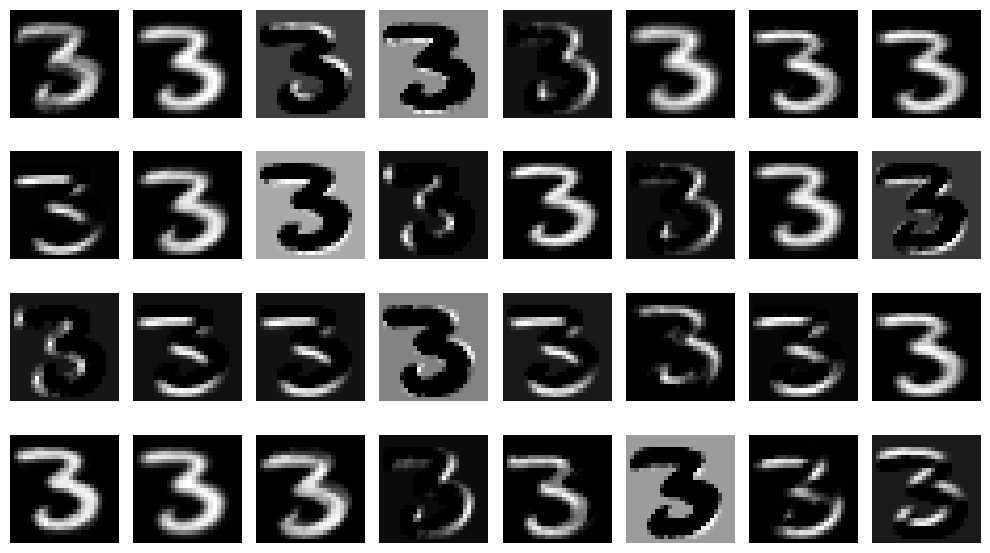

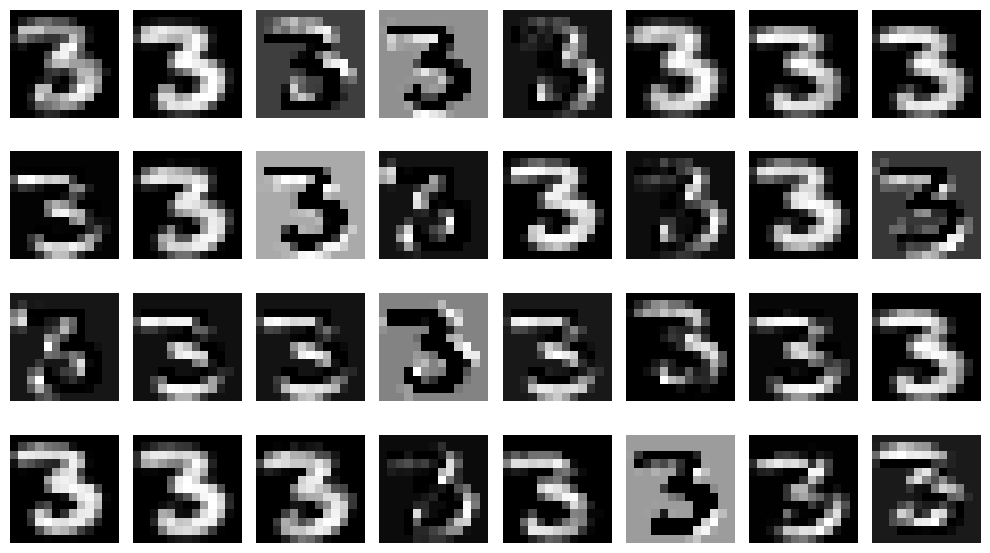

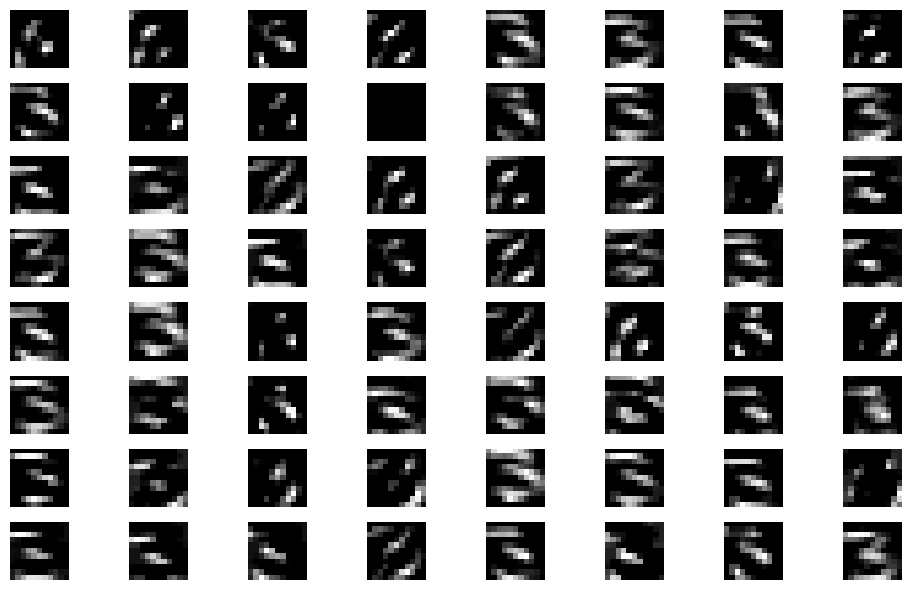

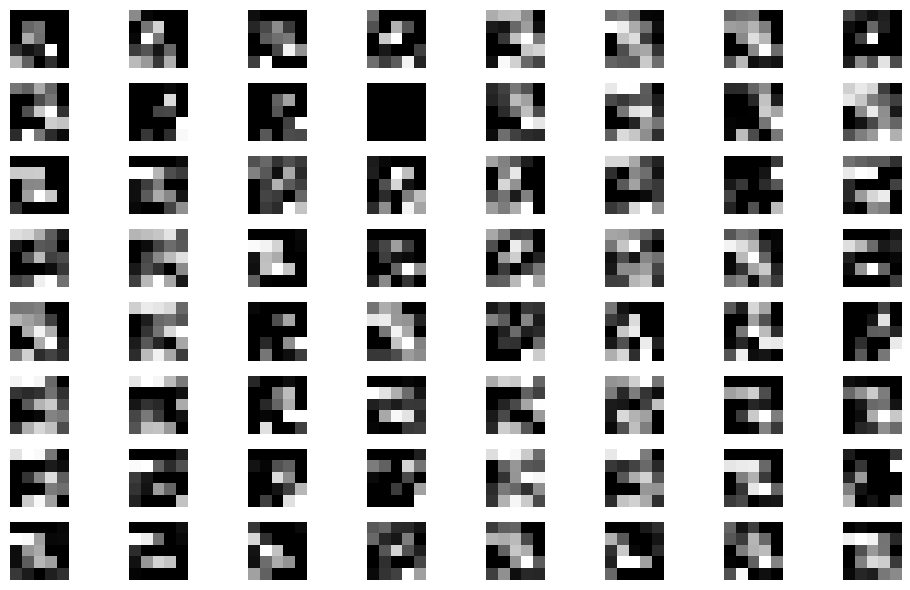

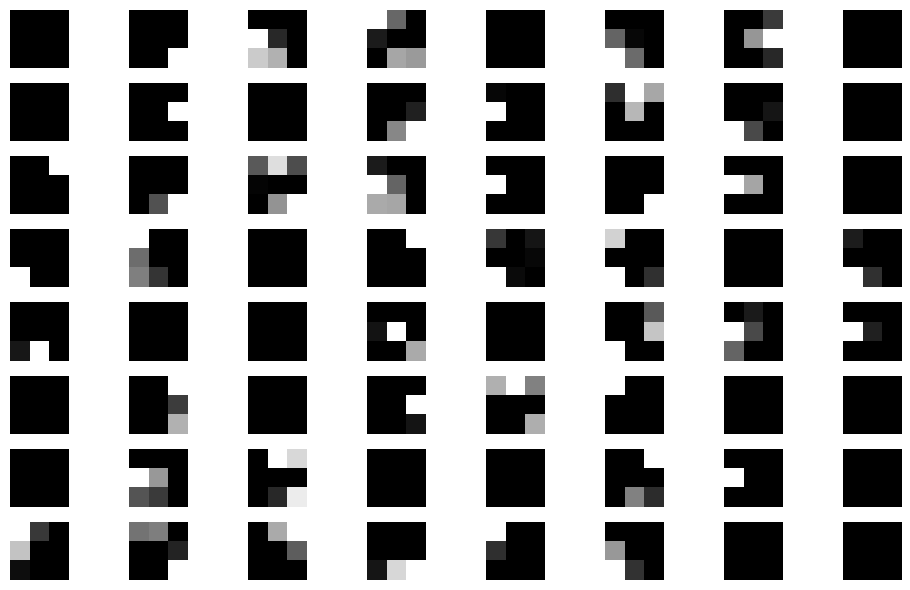

In [73]:
for j in range(5):
    fig_shape = activations[j].shape
    s = int(fig_shape[3] / 32)
    fig = plt.figure(figsize=(10, 6))
    for i in range(fig_shape[3]):
        ax = fig.add_subplot(s * 4, 8, (i + 1))
        plt.imshow(
            activations[j].reshape((fig_shape[1], fig_shape[2], fig_shape[3]))[:, :, i],
            cmap="gray",
        )
        ax.axis("off")
    plt.tight_layout()
    plt.show()

In [74]:
## Define the Sequential model as usual.
nns = models.Sequential([
    keras.Input(shape=(28, 28, 1)),
    ## Add convolutional layers with 'same' padding
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    ## Flatten feature map for dense classifier
    layers.Flatten(),
    layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(0.01)),
    Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])

nns.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       200,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 257,162 (1004.54 KB)

 Trainable params: 257,162 (1004.54 KB)

 Non-trainable params: 0 (0.00 B)

In [75]:
## Compile the model
nr.seed(2323)
set_random_seed(4466)
nns.compile(
    optimizer="rmsprop",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

## Now fit the model
nr.seed(88776)
set_random_seed(5666)
history_s = nns.fit(
    train_images,
    train_labels,
    epochs=40,
    batch_size=128,
    validation_data=(test_images, test_labels),
    callbacks=callbacks_list,
    verbose=1,
)

Epoch 1/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 79s 165ms/step - accuracy: 0.8903 - loss: 0.5415 - val_accuracy: 0.9759 - val_loss: 0.1534
Epoch 2/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 77s 165ms/step - accuracy: 0.9617 - loss: 0.2052 - val_accuracy: 0.9776 - val_loss: 0.1274


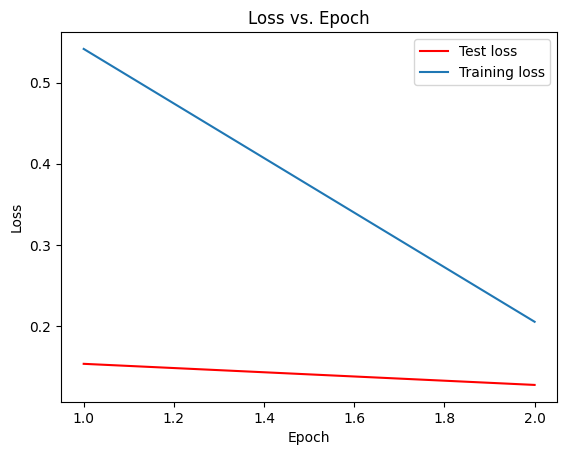

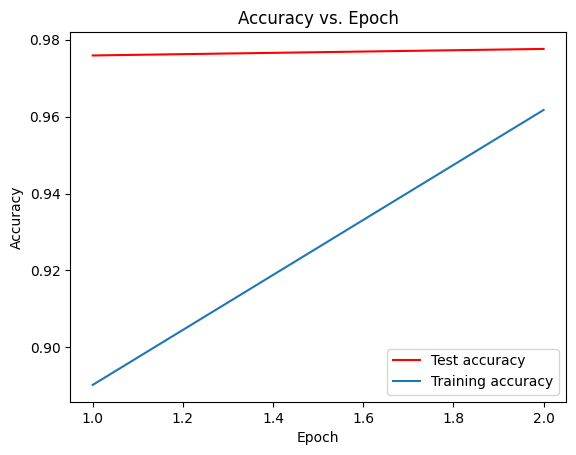

In [76]:
plot_loss(history_s)
plt.show()

plt.figure()
plot_accuracy(history_s)
plt.show()